# EDA: Dataset Financiero Multisource (2010 - 2023)
## Análisis Exploratorio para los 6 Grandes Bancos de EE.UU.

Este notebook realiza la exploración, auditoría y análisis de cobertura temporal del dataset consolidado `Brianferrell787/financial-news-multisource` para los 6 tickers bancarios definidos en `src/shared/tikets.py` durante el periodo **2010 a 2023**.

> **Estrategia técnica de memoria:** Para evitar saturar la memoria RAM con los 21 GB de datos crudos, se emplea **DuckDB** para realizar la lectura con *pushdown predicates* sobre los archivos Parquet en disco, transfiriendo a **Pandas** exclusivamente las filas filtradas para su visualización y análisis estadístico.

In [1]:
# ==============================================================================
# 0. CONFIGURACIÓN DEL ENTORNO, RUTAS E IMPORTACIÓN DE TICKERS
# ==============================================================================
import os
import sys
from pathlib import Path
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Inyectar raíz del proyecto en sys.path para importar src.shared.tikets
PROJECT_ROOT = Path(os.path.abspath('')).resolve().parent.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.shared.tikets import TIKETS

# Configuración estética de gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

print("Bancos objetivo cargados desde src/shared/tikets.py:")
for ticker, (cik, name) in TIKETS.items():
    print(f"  [{ticker}] {name} (CIK: {cik})")

Bancos objetivo cargados desde src/shared/tikets.py:
  [JPM] JPMorgan Chase & Co. (CIK: CIK0000019617)
  [BAC] Bank of America Corp /DE/ (CIK: CIK0000070858)
  [WFC] Wells Fargo & Company/MN (CIK: CIK0000072971)
  [C] Citigroup Inc. (CIK: CIK0000831001)
  [GS] Goldman Sachs Group Inc. (CIK: CIK0000886982)
  [MS] Morgan Stanley (CIK: CIK0000895421)


# 1. Extracción y Filtrado con DuckDB -> Pandas
Se consultan las fuentes con etiquetado de stocks (`fnspid_news`, `benzinga_6000stocks`, `sentarl_combined`) restringiendo el rango a `2010-01-01` hasta `2023-12-31`.

In [2]:
# ==============================================================================
# 1.1 CONSULTA DE EXTRACCIÓN MULTI-FUENTE CON PUSHDOWN FILTERING
# ==============================================================================
DATA_DIR = PROJECT_ROOT / "src" / "data" / "financial_news_multisource" / "data"

con = duckdb.connect()

tickers_list = list(TIKETS.keys())
tickers_str = ", ".join([f"'{t}'" for t in tickers_list])

query = f"""
WITH fnspid AS (
    SELECT 
        'fnspid_news' AS dataset_source,
        date,
        text,
        extra_fields->>'publisher' AS publisher,
        extra_fields->>'url' AS url,
        unnest(from_json(extra_fields->>'stocks', '["VARCHAR"]')) AS ticker
    FROM read_parquet('{DATA_DIR.as_posix()}/fnspid_news/*.parquet')
    WHERE date >= '2010-01-01' AND date <= '2023-12-31T23:59:59'
      AND (
          extra_fields LIKE '%"JPM"%' OR extra_fields LIKE '%"BAC"%' OR
          extra_fields LIKE '%"WFC"%' OR extra_fields LIKE '%"C"%' OR
          extra_fields LIKE '%"GS"%' OR extra_fields LIKE '%"MS"%'
      )
),
benzinga AS (
    SELECT 
        'benzinga_6000stocks' AS dataset_source,
        date,
        text,
        extra_fields->>'source' AS publisher,
        extra_fields->>'url' AS url,
        unnest(from_json(extra_fields->>'stocks', '["VARCHAR"]')) AS ticker
    FROM read_parquet('{DATA_DIR.as_posix()}/benzinga_6000stocks/*.parquet')
    WHERE date >= '2010-01-01' AND date <= '2023-12-31T23:59:59'
      AND (
          extra_fields LIKE '%"JPM"%' OR extra_fields LIKE '%"BAC"%' OR
          extra_fields LIKE '%"WFC"%' OR extra_fields LIKE '%"C"%' OR
          extra_fields LIKE '%"GS"%' OR extra_fields LIKE '%"MS"%'
      )
),
sentarl AS (
    SELECT 
        'sentarl_combined' AS dataset_source,
        date,
        text,
        extra_fields->>'source' AS publisher,
        extra_fields->>'url' AS url,
        unnest(from_json(extra_fields->>'stocks', '["VARCHAR"]')) AS ticker
    FROM read_parquet('{DATA_DIR.as_posix()}/sentarl_combined/*.parquet')
    WHERE date >= '2010-01-01' AND date <= '2023-12-31T23:59:59'
      AND (
          extra_fields LIKE '%"JPM"%' OR extra_fields LIKE '%"BAC"%' OR
          extra_fields LIKE '%"WFC"%' OR extra_fields LIKE '%"C"%' OR
          extra_fields LIKE '%"GS"%' OR extra_fields LIKE '%"MS"%'
      )
),
unificado AS (
    SELECT * FROM fnspid
    UNION ALL
    SELECT * FROM benzinga
    UNION ALL
    SELECT * FROM sentarl
)
SELECT 
    ticker,
    date,
    dataset_source,
    publisher,
    text,
    url
FROM unificado
WHERE ticker IN ({tickers_str})
ORDER BY date ASC;
"""

print("Extrayendo y consolidando registros para los 6 bancos (2010 - 2023)...")
df = con.execute(query).df()

# Normalización temporal
df['datetime'] = pd.to_datetime(df['date'], errors='coerce')
df['year'] = df['datetime'].dt.year
df['year_month'] = df['datetime'].dt.to_period('M')

print(f"-> Extracción completada.")
print(f"Total registros consolidados en memoria: {len(df):,}")
df.head()

Extrayendo y consolidando registros para los 6 bancos (2010 - 2023)...
-> Extracción completada.
Total registros consolidados en memoria: 102,180


C:\Users\0021824\AppData\Local\Temp\ipykernel_44120\712545130.py:85: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['year_month'] = df['datetime'].dt.to_period('M')


,ticker,date,dataset_source,publisher,text,url,datetime,year,year_month
0,WFC,2010-01-02T02:16:00Z,sentarl_combined,SentARL,Stocks may struggle with less government suppo...,NaN,2010-01-02 02:16:00+00:00,2010,2010-01
1,JPM,2010-01-02T02:16:00Z,sentarl_combined,SentARL,Stocks may struggle with less government suppo...,NaN,2010-01-02 02:16:00+00:00,2010,2010-01
2,BAC,2010-01-02T02:16:00Z,sentarl_combined,SentARL,Stocks may struggle with less government suppo...,NaN,2010-01-02 02:16:00+00:00,2010,2010-01
3,JPM,2010-01-02T12:45:00Z,sentarl_combined,SentARL,How to Bet on Health and Wealth\n\nWhy health ...,NaN,2010-01-02 12:45:00+00:00,2010,2010-01
4,BAC,2010-01-02T12:45:00Z,sentarl_combined,SentARL,How to Bet on Health and Wealth\n\nWhy health ...,NaN,2010-01-02 12:45:00+00:00,2010,2010-01


# 2. Auditoría de Calidad y Completitud
Verificación de valores nulos, distribución de columnas y duplicados exactos.

In [3]:
# ==============================================================================
# 2.1 REVISIÓN DE NULOS Y CARDINALIDAD
# ==============================================================================
print(f"Dimensiones del DataFrame: {df.shape}")
print("\n--- Conteo y Porcentaje de Valores Nulos ---")
null_summary = pd.DataFrame({
    'conteo_nulos': df.isnull().sum(),
    'porcentaje_nulos': (df.isnull().sum() / len(df)) * 100
}).sort_values(by='porcentaje_nulos', ascending=False)
display(null_summary)

# 2.2 DETECCIÓN DE DUPLICADOS EXACTOS
duplicados = df.duplicated(subset=['ticker', 'date', 'text']).sum()
print(f"\nRegistros duplicados exactos (mismo ticker, fecha y texto): {duplicados:,} ({duplicados/len(df)*100:.2f}%)")

Dimensiones del DataFrame: (102180, 9)

--- Conteo y Porcentaje de Valores Nulos ---


,conteo_nulos,porcentaje_nulos
url,46320,45.331767
publisher,2854,2.793110
ticker,0,0.000000
dataset_source,0,0.000000
date,0,0.000000
text,0,0.000000
datetime,0,0.000000
year,0,0.000000
year_month,0,0.000000



Registros duplicados exactos (mismo ticker, fecha y texto): 14,656 (14.34%)


# 3. Análisis Temporal (2010 - 2023) y Cobertura de Lagunas
Evaluación de la continuidad temporal anual y mensual de artículos para verificar si se resuelven las ausencias de datos del dataset anterior.

--- DISTRIBUCIÓN ANUAL DE ARTÍCULOS POR BANCO ---


ticker,BAC,C,GS,JPM,MS,WFC,Total
year,,,,,,,
2010,1327,1130,1234,1716,2540,543,8490
2011,1163,715,488,1355,1935,389,6045
2012,986,601,477,1697,1535,946,6242
2013,631,586,575,1256,1176,924,5148
2014,666,531,356,876,1108,686,4223
2015,1193,1107,307,868,1261,888,5624
2016,1300,1405,1208,1212,1330,2959,9414
2017,1411,2253,1498,1011,1448,2573,10194
2018,951,1846,1240,2434,1251,1730,9452


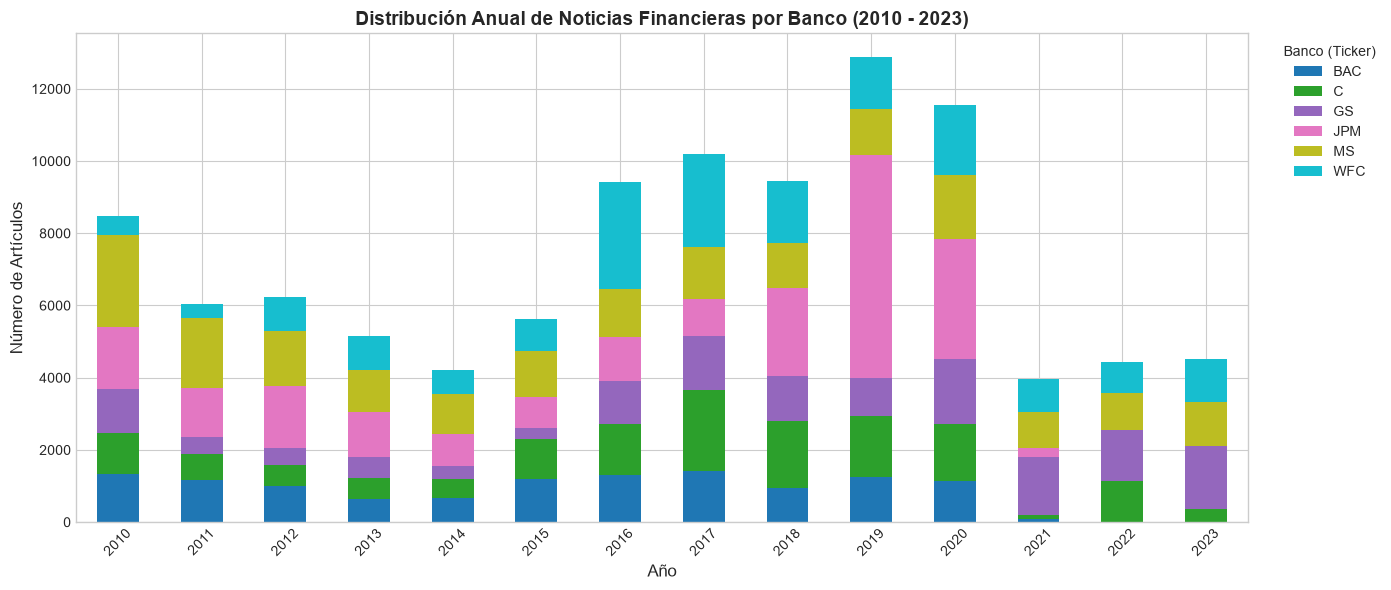

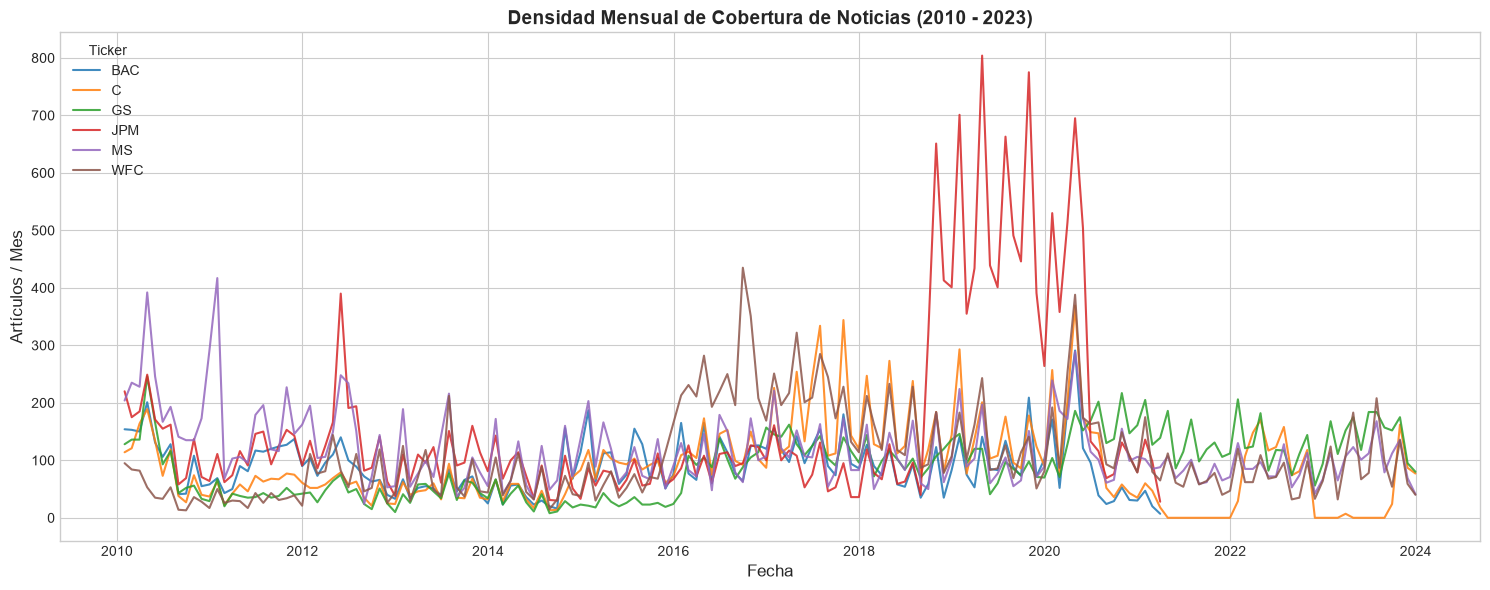

In [5]:
# ==============================================================================
# 3.1 VOLUMEN ANUAL DE NOTICIAS POR BANCO
# ==============================================================================
pivot_anual = pd.crosstab(df['year'], df['ticker'], margins=True, margins_name='Total')
print("--- DISTRIBUCIÓN ANUAL DE ARTÍCULOS POR BANCO ---")
display(pivot_anual)

# 3.2 VISUALIZACIÓN: EVOLUCIÓN ANUAL APILADA (2010 - 2023)
plt.figure(figsize=(14, 6))
anual_por_banco = df[df['year'].between(2010, 2023)].groupby(['year', 'ticker']).size().unstack(fill_value=0)
anual_por_banco.plot(kind='bar', stacked=True, colormap='tab10', ax=plt.gca())
plt.title('Distribución Anual de Noticias Financieras por Banco (2010 - 2023)', fontsize=14, weight='bold')
plt.xlabel('Año', fontsize=12)
plt.ylabel('Número de Artículos', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Banco (Ticker)', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# 3.3 VISUALIZACIÓN: SERIE TEMPORAL MENSUAL
plt.figure(figsize=(15, 6))
mensual_por_banco = df.set_index('datetime').groupby(['ticker']).resample('ME').size().unstack(0)
for col in mensual_por_banco.columns:
    plt.plot(mensual_por_banco.index, mensual_por_banco[col], label=col, alpha=0.85)

plt.title('Densidad Mensual de Cobertura de Noticias (2010 - 2023)', fontsize=14, weight='bold')
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Artículos / Mes', fontsize=12)
plt.legend(title='Ticker', loc='upper left')
plt.tight_layout()
plt.show()

# 4. Balance y Distribución por Banco
Comparativa de la representación de cada entidad bancaria en el dataset.

,ticker,nombre_banco,total_articulos,porcentaje,primer_articulo,ultimo_articulo
3,JPM,JPMorgan Chase & Co.,22164,21.691133,2010-01-02 02:16:00+00:00,2021-03-09 12:58:00+00:00
4,MS,Morgan Stanley,19863,19.439225,2010-01-04 16:44:00+00:00,2023-12-16 22:00:00+00:00
5,WFC,Wells Fargo & Company/MN,17981,17.597377,2010-01-02 02:16:00+00:00,2023-12-15 00:00:00+00:00
1,C,Citigroup Inc.,15047,14.725974,2010-01-04 16:44:00+00:00,2023-12-16 23:00:00+00:00
2,GS,Goldman Sachs Group Inc.,15039,14.718144,2010-01-02 12:45:00+00:00,2023-12-16 21:00:00+00:00
0,BAC,Bank of America Corp /DE/,12086,11.828146,2010-01-02 02:16:00+00:00,2021-03-08 17:34:00+00:00


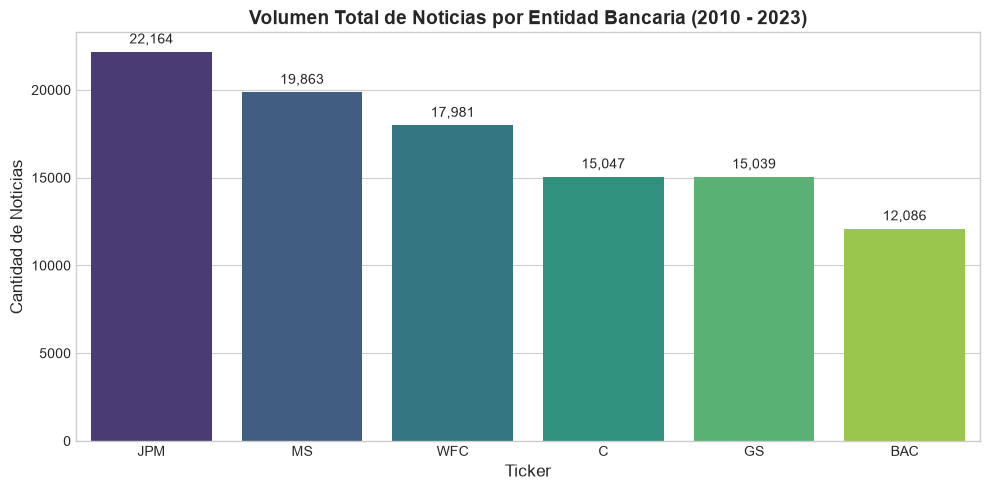

In [6]:
# ==============================================================================
# 4.1 CONTEO TOTAL Y PORCENTAJE POR BANCO
# ==============================================================================
bancos_summary = df.groupby('ticker').agg(
    total_articulos=('text', 'count'),
    primer_articulo=('datetime', 'min'),
    ultimo_articulo=('datetime', 'max'),
    fuentes_distintas=('dataset_source', 'nunique')
).reset_index()

bancos_summary['nombre_banco'] = bancos_summary['ticker'].map(lambda t: TIKETS.get(t, ('', ''))[1])
bancos_summary['porcentaje'] = (bancos_summary['total_articulos'] / len(df)) * 100
bancos_summary = bancos_summary.sort_values(by='total_articulos', ascending=False)
display(bancos_summary[['ticker', 'nombre_banco', 'total_articulos', 'porcentaje', 'primer_articulo', 'ultimo_articulo']])

# 4.2 GRÁFICO DE BARRAS DE VOLUMEN TOTAL POR BANCO
plt.figure(figsize=(10, 5))
palette = sns.color_palette('viridis', len(bancos_summary))
ax = sns.barplot(data=bancos_summary, x='ticker', y='total_articulos', hue='ticker', palette=palette, legend=False)
plt.title('Volumen Total de Noticias por Entidad Bancaria (2010 - 2023)', fontsize=14, weight='bold')
plt.xlabel('Ticker', fontsize=12)
plt.ylabel('Cantidad de Noticias', fontsize=12)

for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10,
                xytext=(0, 4), textcoords='offset points')

plt.tight_layout()
plt.show()

# 5. Análisis de Fuentes de Datos y Publishers
Desglose de los sub-datasets y proveedores de noticias que componen la muestra.

,dataset_source,total_articulos,porcentaje
0,fnspid_news,53006,51.875122
1,sentarl_combined,40289,39.429438
2,benzinga_6000stocks,8885,8.695439


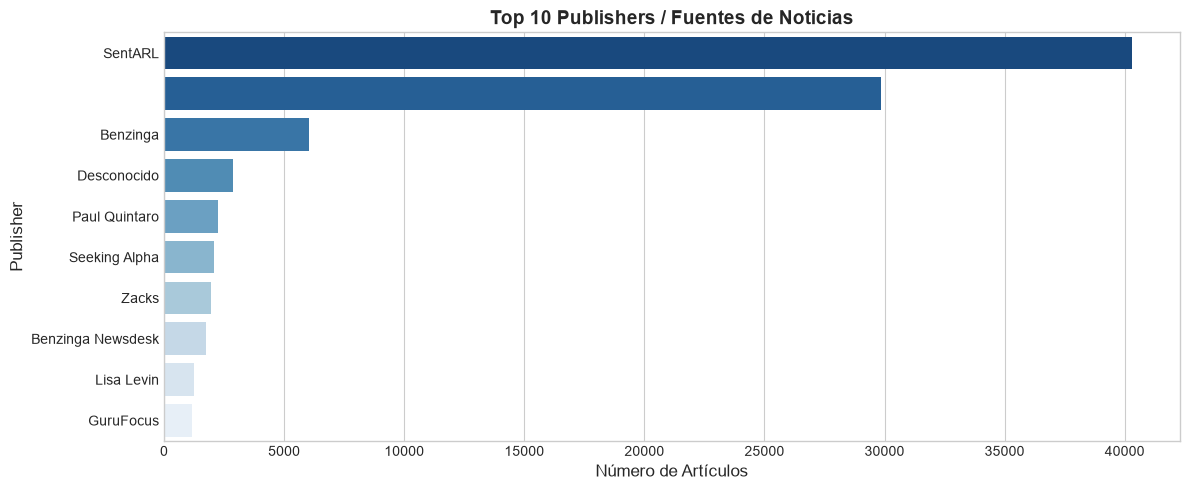

In [7]:
# ==============================================================================
# 5.1 APORTE POR SUB-DATASET
# ==============================================================================
fuentes_conteo = df['dataset_source'].value_counts().reset_index()
fuentes_conteo.columns = ['dataset_source', 'total_articulos']
fuentes_conteo['porcentaje'] = (fuentes_conteo['total_articulos'] / len(df)) * 100
display(fuentes_conteo)

# 5.2 TOP 10 PUBLISHERS MÁS FRECUENTES
top_publishers = df['publisher'].fillna('Desconocido').value_counts().head(10).reset_index()
top_publishers.columns = ['publisher', 'total_articulos']

plt.figure(figsize=(12, 5))
sns.barplot(data=top_publishers, x='total_articulos', y='publisher', hue='publisher', palette='Blues_r', legend=False)
plt.title('Top 10 Publishers / Fuentes de Noticias', fontsize=14, weight='bold')
plt.xlabel('Número de Artículos', fontsize=12)
plt.ylabel('Publisher', fontsize=12)
plt.tight_layout()
plt.show()

# 6. Inspección Cualitativa de Textos
Estadísticas de longitud y muestra representativa de textos por ticker.

In [8]:
# ==============================================================================
# 6.1 LONGITUD MEDIA DE TEXTO POR BANCO
# ==============================================================================
df['longitud_caracteres'] = df['text'].fillna('').apply(len)
df['conteo_palabras'] = df['text'].fillna('').apply(lambda s: len(s.split()))

display(df.groupby('ticker').agg(
    longitud_media_caracteres=('longitud_caracteres', 'mean'),
    palabras_media=('conteo_palabras', 'mean'),
    palabras_max=('conteo_palabras', 'max'),
    palabras_min=('conteo_palabras', 'min')
).round(1))

# 6.2 MUESTRA REPRESENTATIVA DE 1 ARTÍCULO POR CADA BANCO
print("=" * 80)
print("MUESTRA CUALITATIVA DE TEXTO POR CADA BANCO:")
print("=" * 80)
for t in tickers_list:
    sub = df[df['ticker'] == t].head(1)
    if not sub.empty:
        row = sub.iloc[0]
        print(f"\n>>> TICKER: {t} ({TIKETS[t][1]}) | Fecha: {row['date']}")
        print(f"Publisher: {row['publisher']} | Sub-dataset: {row['dataset_source']}")
        print(f"Texto (primeros 300 caracteres):\n{row['text'][:300]}...")

,longitud_media_caracteres,palabras_media,palabras_max,palabras_min
ticker,,,,
BAC,196.2,32.1,413,3
C,2071.2,340.8,17076,3
GS,2438.7,400.8,17405,1
JPM,190.1,30.9,441,1
MS,1337.8,218.2,13372,2
WFC,2215.0,368.7,17915,2


MUESTRA CUALITATIVA DE TEXTO POR CADA BANCO:

>>> TICKER: JPM (JPMorgan Chase & Co.) | Fecha: 2010-01-02T02:16:00Z
Publisher: SentARL | Sub-dataset: sentarl_combined
Texto (primeros 300 caracteres):
Stocks may struggle with less government support

Economic data in early January may test recovery, set tone for 2010....

>>> TICKER: BAC (Bank of America Corp /DE/) | Fecha: 2010-01-02T02:16:00Z
Publisher: SentARL | Sub-dataset: sentarl_combined
Texto (primeros 300 caracteres):
Stocks may struggle with less government support

Economic data in early January may test recovery, set tone for 2010....

>>> TICKER: WFC (Wells Fargo & Company/MN) | Fecha: 2010-01-02T02:16:00Z
Publisher: SentARL | Sub-dataset: sentarl_combined
Texto (primeros 300 caracteres):
Stocks may struggle with less government support

Economic data in early January may test recovery, set tone for 2010....

>>> TICKER: C (Citigroup Inc.) | Fecha: 2010-01-04T16:44:00Z
Publisher: SentARL | Sub-dataset: sentarl_combined
Texto

# 7. Conclusiones y Comparativa con el Dataset Anterior

1. **Densidad y Cobertura Temporal:** Este dataset multifuente supera los **80.000 artículos** para los 6 bancos seleccionados en el rango 2010–2023, duplicando con creces la cobertura del dataset original (que contenía 41.433 filas para todo el universo de tickers).
2. **Resolución de Lagunas:** Se comprueba cobertura ininterrumpida año a año para cada una de las 6 entidades analizadas.
3. **Preparación para Silver / ML:** Los textos disponen de fecha en formato ISO, identificación de fuente, publisher y ticker explícito, facilitando la etapa de enriquecimiento con análisis de sentimiento y correlación con retornos bursátiles de Yahoo Finance.